## EU REED 

### Setup Project in Brightway

In [1]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config

import matplotlib.pyplot as plt
import d3graph
import polyviz

15:32:23+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [2]:
config = Config()

In [3]:
bd.projects.set_current(config.PROJECT_NAME)

In [4]:
import import_db

In [5]:
bd.databases

Databases dictionary with 4 object(s):
	bonsai_231231
	bonsai_231231 biosphere
	ecoinvent-3.10-biosphere
	reed

### Import Databases

In [6]:
bonsai = bd.Database('bonsai_231231')
bonsai_bio = bd.Database('bonsai_231231 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')
reed = bd.Database('reed')

In [7]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20251015.xlsx',)
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.write_database()

Extracted 2 worksheets in 0.33 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields


100%|██████████| 14/14 [00:00<00:00, 964.59it/s]


15:32:26+0200 [info     ] Vacuuming database            
Created database: reed


In [8]:
pd.DataFrame(importer.unlinked)

""


In [9]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [10]:
from IPython.display import display
display(df_reed)

,code,comment,location,production amount,reference product,unit,name,worksheet name,database,type,id
0,welding,process modelled as foreground activity,DE,1,welding,meter,welding,LCA,reed,processwithreferenceproduct,239742837747900424
1,"flamecutting, natural gas, meter",This process represents flamecutting. The data...,DE,1,"flamecutting, natural gas, meter",meter,"flamecutting, natural gas, meter",LCA,reed,processwithreferenceproduct,239742837747900418
2,bending,process modelled as foreground activity,DE,1,bending,hour,bending,LCA,reed,processwithreferenceproduct,239742837747900422
3,"flamecutting, lpg, hour",This process represents flamecutting. The data...,DE,1,"flamecutting, lpg, hour",hour,"flamecutting, lpg, hour",LCA,reed,processwithreferenceproduct,239742837747900420
4,"soraluce machine, Komatsu",This process represents the materials for the ...,GB,1,"soraluce machine, Komatsu",unit,"soraluce machine, Komatsu",LCA,reed,processwithreferenceproduct,239742837684985859
5,cast iron production,proxy,CN,1,cast iron production,kilogram,cast iron production,LCA,reed,processwithreferenceproduct,239742837684985857
6,electricity production,proxy,ES,1,electricity production,kilowatt hour,electricity production,LCA,reed,processwithreferenceproduct,239742837684985858
7,"flamecutting, lpg, meter",This process represents flamecutting. The data...,DE,1,"flamecutting, lpg, meter",meter,"flamecutting, lpg, meter",LCA,reed,processwithreferenceproduct,239742837747900417
8,"soraluce machine, Goimek",This process represents the materials for the ...,DE,1,"soraluce machine, Goimek",unit,"soraluce machine, Goimek",LCA,reed,processwithreferenceproduct,239742837747900416
9,"soraluce machine, WWR",This process represents the materials for the ...,DE,1,"soraluce machine, WWR",unit,"soraluce machine, WWR",LCA,reed,processwithreferenceproduct,239742837684985860


### Explore databases

In [11]:
bonsai.search('basic iron and steel and of ferro-alloys and first products thereof')

['basic iron and steel and of ferro-alloys and first products thereof' (tonne, IN, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, CH, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, MT, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, NL, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, IT, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, GB, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, RU, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, FI, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, US, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, LV, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, CA, None),
 'basic ir

In [12]:
reed.search('Flamecutting')

['flamecutting, lpg, hour' (hour, DE, None),
 'flamecutting, lpg, meter' (meter, DE, None),
 'flamecutting, natural gas, meter' (meter, DE, None),
 'flamecutting, natural gas, hour' (hour, DE, None)]

In [13]:
bonsai_bio.search('carbon')

['carbon dioxide accelerated' (tonne, None, ('air',))]

### Initial LCA scores

In [14]:
lpg = bonsai.get(name = 'Liquefied Petroleum Gases (LPG), combustion of', location = "DE", unit = 'TJ')
steel = bonsai.get(name = 'basic iron and steel and of ferro-alloys and first products thereof', location = "DK", unit = 'tonne')

In [15]:
check_activity_type = print(lpg["activity type"])

transforming activity


In [16]:
# export the LCI to Microsoft Excel in an overview format
bi.export.excel.write_lci_excel(bonsai.name, objs=[steel], dirpath=Path.cwd())

'c:\\Users\\TimWeber\\repos_20LCA\\REED\\reed\\scripts\\lci-bonsai_231231.xlsx'

In [17]:
# print metadata fields of the process
fields = [
    "name", "location", "unit",
    "comment", "sources", "authors",
    "dataset author", "data generator", "activity type"
]
 
for f in fields:
    if f in lpg:
        print(f"{f}: {lpg[f]}")
 

name: Liquefied Petroleum Gases (LPG), combustion of
location: DE
unit: TJ
activity type: transforming activity


In [18]:
steel_lca = steel.lca(config.lcia_gwp100)
steel_lca.score

1853.302687777272

In [19]:
welding_lca = welding.lca(config.lcia_gwp100)
welding_lca.score

NameError: name 'welding' is not defined

In [ ]:
soraluce_wwr_lca = soraluce_wwr.lca(config.lcia_gwp100)
soraluce_wwr_lca.score

### Contribution analysis

In [ ]:
bwa.print_recursive_calculation(steel,
lcia_method=config.lcia_gwp100,max_level=5,cutoff=0.01)

In [ ]:
# Just another way to calculate and display the contribution analysis, in case you want to extract to EXCEL etc.
steel_ca = bwa.utils.recursive_calculation_to_object(steel,
                                          lcia_method=config.lcia_gwp100,
                                          max_level=1,
                                          cutoff=0.02,
                                          as_dataframe=True,
                                          )
steel_ca

In [ ]:
bwa.print_recursive_calculation(soraluce_wwr,
lcia_method=config.lcia_gwp100,max_level=5,cutoff=0.01)

### Plotting the contribution analysis

In [ ]:
# Filter out the parent processes that are not relevant for the contribution analysis
steel_ca = steel_ca.dropna(subset='parent') 

In [ ]:
# First, we plot the contribution analysis for the brigthway ceramics production process
f, ax = plt.subplots(figsize=(6, 3))
sns.barplot(y='name', x='score', data=steel_ca, ax=ax)
ax.set(
    title='Contribution analysis for the demand of 1 FU of the produt under study',
    xlabel='CO2 eq. emissions (kg)',
    ylabel='')
plt.tight_layout()
plt.show()


### Supplementary material from ecoinvent

In [ ]:
arc_welding_ecoinvent = 0.2020495074178421

This graph is extracted using ecoinvent v3.10 consequential and brightway 2.5 and can help us identify key processes to study when modelling the foreground of REED

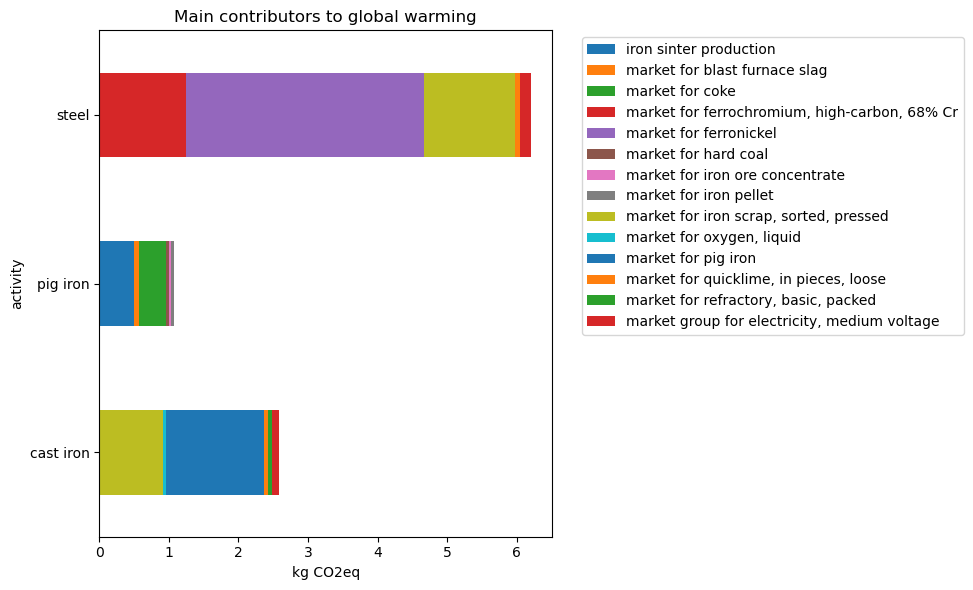

This graph compares arc metal welding and gas welding from ecoinvent and shows that most of the climate impact is from the filler material in all cases

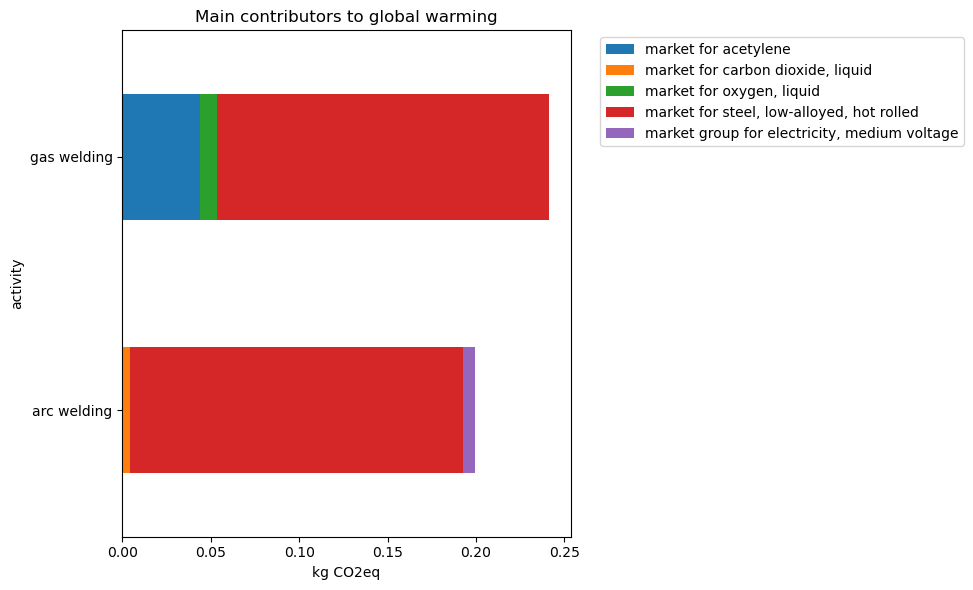